#  Paisabazar Risk And Fraud Detection


## Business Problem

Financial institutions such as Paisabazaar manage large volumes of customer financial data. Poor data quality can negatively impact business decisions, customer risk assessment, loan approval, and predictive modeling.

Before performing any analysis or building machine learning models, it is essential to validate the dataset by checking its completeness, consistency, and integrity. A reliable dataset forms the foundation for accurate business insights and predictive analytics.

#### 1. Data Overview

##### Data


In [1]:
# Importing Libraries

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import warnings 
warnings.filterwarnings("ignore")

In [2]:
# Loading Dataset

df = pd.read_csv(r"../data/paisabazar_dataset.csv")

#### Data Validation


In [3]:
# Viewing Data
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


In [4]:
# total Roes and column  
df.shape

(100000, 28)

In [5]:
# viewing middle Data to see bias
df.sample(5, random_state=42)

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
75721,119215,13625,2,an Arakalid,30.0,995314669.0,Manager,43391.96,3688.996667,1.0,...,Good,1468.28,29.112468,284.0,No,0.000000,47.438673,High_spent_Large_value_payments,554.930282,Good
80184,125910,34582,1,Matthewz,18.0,185998068.0,Scientist,14351.21,1274.934167,8.0,...,Bad,4766.87,39.849732,98.0,Yes,61.098718,21.200962,Low_spent_Small_value_payments,238.314485,Poor
19864,35430,8668,1,Tom Miless,41.0,241538475.0,Developer,130125.04,10871.753333,5.0,...,Good,1195.05,21.542892,191.0,No,204.285650,103.431653,Low_spent_Small_value_payments,271.756987,Good
76699,120681,13011,4,Lisaa,35.0,204786176.0,Manager,20107.21,1631.600833,6.0,...,Standard,2544.60,32.423759,232.0,Yes,27.106395,10.917189,Low_spent_Small_value_payments,359.233914,Poor
92991,145117,44461,8,Masond,27.0,27116852.0,Doctor,92186.19,7487.182500,1.0,...,Good,809.01,39.543131,249.0,No,185.797654,84.280516,High_spent_Medium_value_payments,697.400557,Good


In [6]:
# data Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  str    
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  str    
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  str    
 14  

##### During data type check we found so many variables which needs a datatype conversion like id , customer id , age and so on but we only convert the important and necessary column like 'age' , 'no of loans' and more which we use in our model.

In [7]:
# mising null values
df.isnull().sum()

ID                          0
Customer_ID                 0
Month                       0
Name                        0
Age                         0
SSN                         0
Occupation                  0
Annual_Income               0
Monthly_Inhand_Salary       0
Num_Bank_Accounts           0
Num_Credit_Card             0
Interest_Rate               0
Num_of_Loan                 0
Type_of_Loan                0
Delay_from_due_date         0
Num_of_Delayed_Payment      0
Changed_Credit_Limit        0
Num_Credit_Inquiries        0
Credit_Mix                  0
Outstanding_Debt            0
Credit_Utilization_Ratio    0
Credit_History_Age          0
Payment_of_Min_Amount       0
Total_EMI_per_month         0
Amount_invested_monthly     0
Payment_Behaviour           0
Monthly_Balance             0
Credit_Score                0
dtype: int64

In [8]:
# duplicate values
df.duplicated().sum()

np.int64(0)

In [9]:
df.shape

(100000, 28)

### EDA

#### Knowing Columns of dataset

In [10]:
# Knowing Column

df.columns

Index(['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation',
       'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score'],
      dtype='str')

In [11]:
# dataset Description
df.describe(include="all")

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
count,100000.000000,100000.000000,100000.000000,100000,100000.000000,1.000000e+05,100000,100000.000000,100000.000000,100000.000000,...,100000,100000.000000,100000.000000,100000.000000,100000,100000.000000,100000.000000,100000,100000.000000,100000
unique,NaN,NaN,NaN,10128,NaN,NaN,15,NaN,NaN,NaN,...,3,NaN,NaN,NaN,3,NaN,NaN,6,NaN,3
top,NaN,NaN,NaN,Langep,NaN,NaN,Lawyer,NaN,NaN,NaN,...,Standard,NaN,NaN,NaN,Yes,NaN,NaN,Low_spent_Small_value_payments,NaN,Standard
freq,NaN,NaN,NaN,48,NaN,NaN,7096,NaN,NaN,NaN,...,45848,NaN,NaN,NaN,52326,NaN,NaN,28616,NaN,53174
mean,80631.500000,25982.666640,4.500000,NaN,33.316340,5.004617e+08,NaN,50505.123449,4197.270835,5.368820,...,NaN,1426.220376,32.285173,221.220460,NaN,107.699208,55.101315,NaN,392.697586,NaN
std,43301.486619,14340.543051,2.291299,NaN,10.764812,2.908267e+08,NaN,38299.422093,3186.432497,2.593314,...,NaN,1155.129026,5.116875,99.680716,NaN,132.267056,39.006932,NaN,201.652719,NaN
min,5634.000000,1006.000000,1.000000,NaN,14.000000,8.134900e+04,NaN,7005.930000,303.645417,0.000000,...,NaN,0.230000,20.000000,1.000000,NaN,0.000000,0.000000,NaN,0.007760,NaN
25%,43132.750000,13664.500000,2.750000,NaN,24.000000,2.451686e+08,NaN,19342.972500,1626.594167,3.000000,...,NaN,566.072500,28.052567,144.000000,NaN,29.268886,27.959111,NaN,267.615983,NaN
50%,80631.500000,25777.000000,4.500000,NaN,33.000000,5.006886e+08,NaN,36999.705000,3095.905000,5.000000,...,NaN,1166.155000,32.305784,219.000000,NaN,66.462304,45.156550,NaN,333.865366,NaN
75%,118130.250000,38385.000000,6.250000,NaN,42.000000,7.560027e+08,NaN,71683.470000,5957.715000,7.000000,...,NaN,1945.962500,36.496663,302.000000,NaN,147.392573,71.295797,NaN,463.215683,NaN


#### The dataset contains 100,000 complete customer profile records tracking a financial metrics feature across a range from 5,634 to 155,629, which exhibits a perfectly symmetric, unskewed uniform distribution with zero outliers due to a nearly identical mean (80,000) and median (80,361).

In [12]:
df.nunique()

ID                          100000
Customer_ID                  12500
Month                            8
Name                         10128
Age                             43
SSN                          12500
Occupation                      15
Annual_Income                12488
Monthly_Inhand_Salary        13241
Num_Bank_Accounts               12
Num_Credit_Card                 12
Interest_Rate                   34
Num_of_Loan                     10
Type_of_Loan                  6261
Delay_from_due_date             63
Num_of_Delayed_Payment          26
Changed_Credit_Limit          3452
Num_Credit_Inquiries            18
Credit_Mix                       3
Outstanding_Debt             12203
Credit_Utilization_Ratio    100000
Credit_History_Age             404
Payment_of_Min_Amount            3
Total_EMI_per_month          11890
Amount_invested_monthly      12261
Payment_Behaviour                6
Monthly_Balance              98494
Credit_Score                     3
dtype: int64

In [13]:
df.dtypes

ID                            int64
Customer_ID                   int64
Month                         int64
Name                            str
Age                         float64
SSN                         float64
Occupation                      str
Annual_Income               float64
Monthly_Inhand_Salary       float64
Num_Bank_Accounts           float64
Num_Credit_Card             float64
Interest_Rate               float64
Num_of_Loan                 float64
Type_of_Loan                    str
Delay_from_due_date         float64
Num_of_Delayed_Payment      float64
Changed_Credit_Limit        float64
Num_Credit_Inquiries        float64
Credit_Mix                      str
Outstanding_Debt            float64
Credit_Utilization_Ratio    float64
Credit_History_Age          float64
Payment_of_Min_Amount           str
Total_EMI_per_month         float64
Amount_invested_monthly     float64
Payment_Behaviour               str
Monthly_Balance             float64
Credit_Score                

#### Transfroming Data

In [14]:
# All columns in categorical and numerical

numerical_columns = df.select_dtypes(include=[np.number]).columns.tolist()

categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()

print("\n\n\nNumerical Columns"," ",numerical_columns)

print("\nCategorical Columns"," ",categorical_columns)




Numerical Columns   ['ID', 'Customer_ID', 'Month', 'Age', 'SSN', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance']

Categorical Columns   ['Name', 'Occupation', 'Type_of_Loan', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'Credit_Score']


In [15]:
df["Age"] = df["Age"].astype(int)

In [16]:
df["Type_of_Loan"] = df["Type_of_Loan"].astype(str)

In [17]:
df["Delay_from_due_date"] = df["Delay_from_due_date"].astype(int)

In [18]:
df["Num_of_Delayed_Payment"] = df["Num_of_Delayed_Payment"].astype(int)

In [19]:
df["Num_Credit_Inquiries"] = df["Num_Credit_Inquiries"].astype(int)

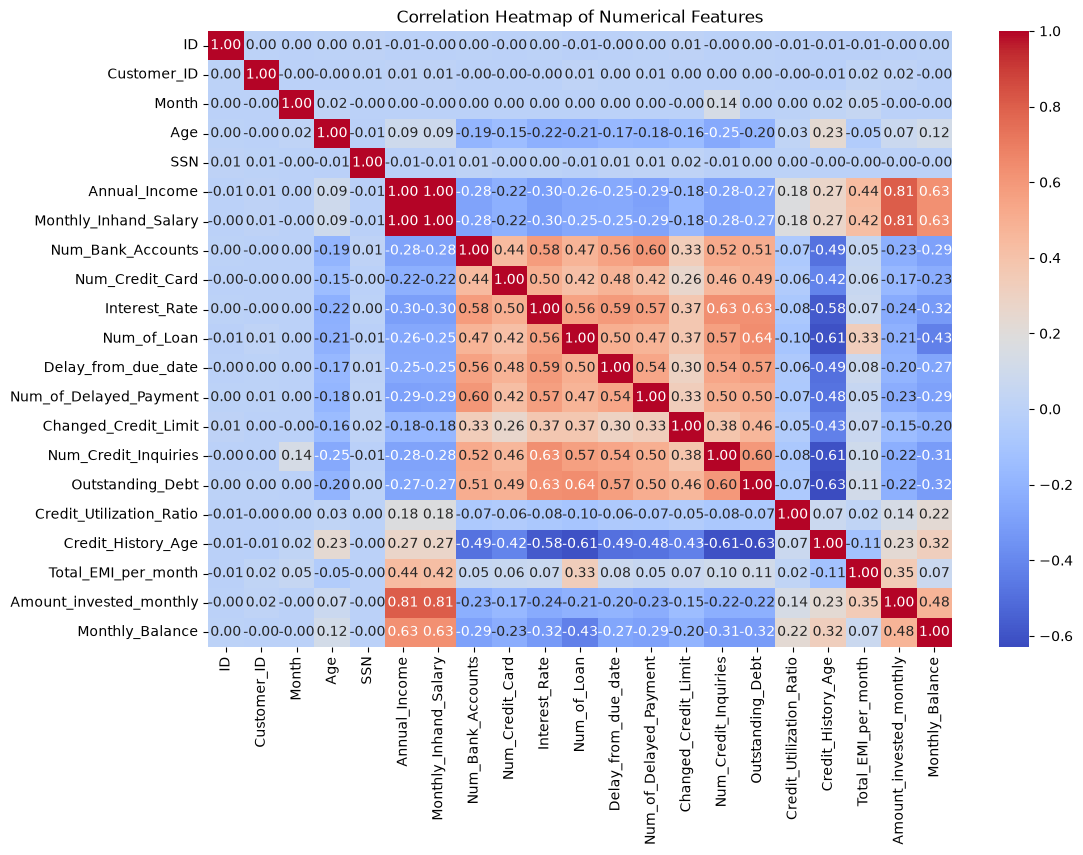

In [20]:
# checking correlation of numerical features
plt.figure(figsize=(12,8))
sns.heatmap(df[numerical_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  str    
 4   Age                       100000 non-null  int64  
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  str    
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  str    
 14  

## -----------------target variable--------------------

In [22]:
df['Credit_Score'].value_counts()

Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: count, dtype: int64

In [23]:
print(df["Credit_Score"])

0            Good
1            Good
2            Good
3            Good
4            Good
           ...   
99995        Poor
99996        Poor
99997        Poor
99998    Standard
99999        Poor
Name: Credit_Score, Length: 100000, dtype: str


In [24]:
(df["Credit_Score"].value_counts(normalize=True).mul(100).round(2))

Credit_Score
Standard    53.17
Poor        29.00
Good        17.83
Name: proportion, dtype: float64

### columns numerical and categorical

### Visualisation

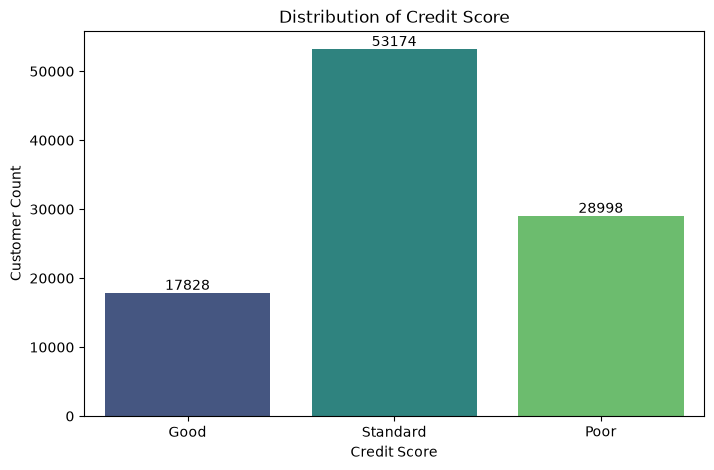

In [25]:
# Distribution of Credit Score
# -----------------------------

plt.figure(figsize=(8,5))
plt.title("Distribution of Credit Score")


ax = sns.countplot(data=df,x="Credit_Score",palette="viridis")

plt.xlabel("Credit Score")
plt.ylabel("Customer Count")

# Add value labels
for container in ax.containers:
    ax.bar_label(container)

plt.show()

### Observation

- The dataset contains three credit score categories.
- The distribution appears reasonably balanced, although one category may have a higher representation.
- Since the target is not heavily imbalanced, standard classification techniques can be evaluated before considering resampling methods.

In [26]:
# Extracting Important column from dataset 

important_numerical = [
    "Age","Annual_Income","Outstanding_Debt","Credit_Utilization_Ratio","Delay_from_due_date","Num_of_Delayed_Payment", "Monthly_Balance"
]

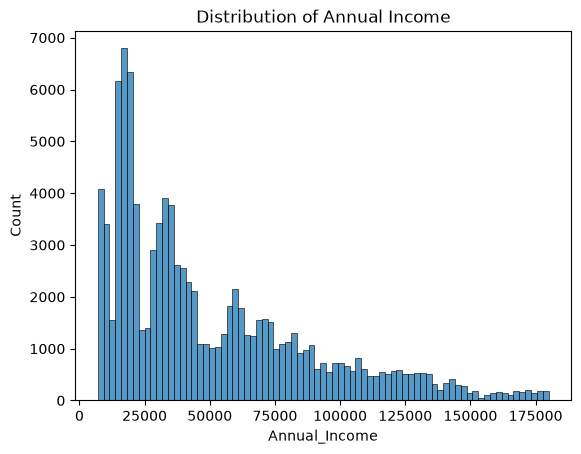

In [27]:
# visualizing annual income as it is a important column 20,12

sns.histplot(df['Annual_Income'])
plt.title('Distribution of Annual Income')
plt.show()

In [28]:
#Removing outliers in "Annual_Income" column using IQR
Q1 = df['Annual_Income'].quantile(0.25)
Q3= df['Annual_Income'].quantile(0.75)
IQR = Q3 - Q1
df = df[(df['Annual_Income'] >= (Q1- 1.5 *IQR) ) & (df['Annual_Income'] <= (Q3 + 1.5 * IQR))]

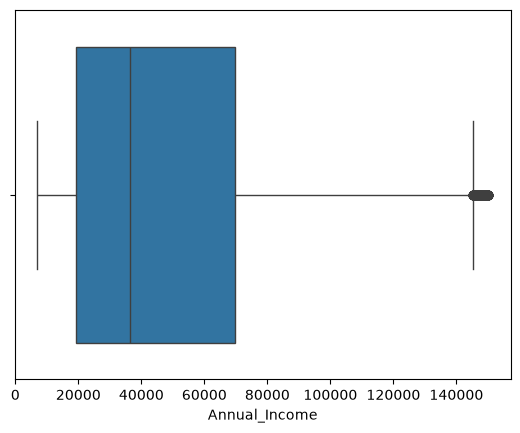

<Figure size 640x480 with 0 Axes>

In [29]:
sns.boxplot(data=df, x = df['Annual_Income'])

plt.show()
plt.tight_layout()

### featuring new column 

In [30]:
df['Income_per_Account'] = df['Annual_Income'] / df['Num_Bank_Accounts']

In [31]:
df['Credit_Score_Level'] = df['Credit_Score'].apply(lambda x:'High' if isinstance(x,( int, float)) and x > 700 else 'Low')

#### plotting credit score vs credit score

<Axes: xlabel='Payment_of_Min_Amount', ylabel='count'>

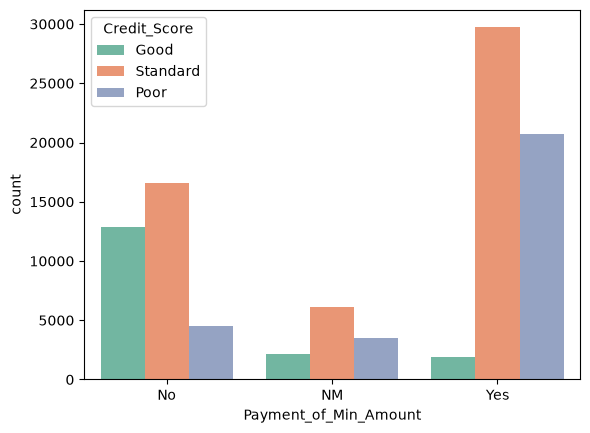

In [32]:
sns.countplot(data=df, x='Payment_of_Min_Amount', hue='Credit_Score', palette='Set2')

In [33]:
df.tail(3)

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,Income_per_Account,Credit_Score_Level
99997,155627,37932,6,Nicks,25,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,41.255522,380.0,No,35.104023,24.028477,High_spent_Large_value_payments,516.809083,Poor,9907.2475,Low
99998,155628,37932,7,Nicks,25,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,33.638208,381.0,No,35.104023,24.028477,Low_spent_Large_value_payments,319.164979,Standard,9907.2475,Low
99999,155629,37932,8,Nicks,25,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,34.192463,382.0,No,35.104023,24.028477,High_spent_Medium_value_payments,393.673696,Poor,9907.2475,Low


In [34]:
df.info()

<class 'pandas.DataFrame'>
Index: 98000 entries, 0 to 99999
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        98000 non-null  int64  
 1   Customer_ID               98000 non-null  int64  
 2   Month                     98000 non-null  int64  
 3   Name                      98000 non-null  str    
 4   Age                       98000 non-null  int64  
 5   SSN                       98000 non-null  float64
 6   Occupation                98000 non-null  str    
 7   Annual_Income             98000 non-null  float64
 8   Monthly_Inhand_Salary     98000 non-null  float64
 9   Num_Bank_Accounts         98000 non-null  float64
 10  Num_Credit_Card           98000 non-null  float64
 11  Interest_Rate             98000 non-null  float64
 12  Num_of_Loan               98000 non-null  float64
 13  Type_of_Loan              98000 non-null  str    
 14  Delay_from_due_date   

### KPIs Calculation

#### Customer Demographics

In [35]:
# avearge age
avg_age = df['Age'].mean()
print(avg_age)

33.267755102040816


In [36]:
# distribution of occupation
occupation_wise_no= df['Occupation'].value_counts()
print(occupation_wise_no)

Occupation
Lawyer           6960
Engineer         6720
Architect        6672
Mechanic         6648
Scientist        6624
Media_Manager    6600
Developer        6592
Accountant       6576
Teacher          6544
Entrepreneur     6496
Doctor           6456
Journalist       6392
Manager          6288
Musician         6216
Writer           6216
Name: count, dtype: int64


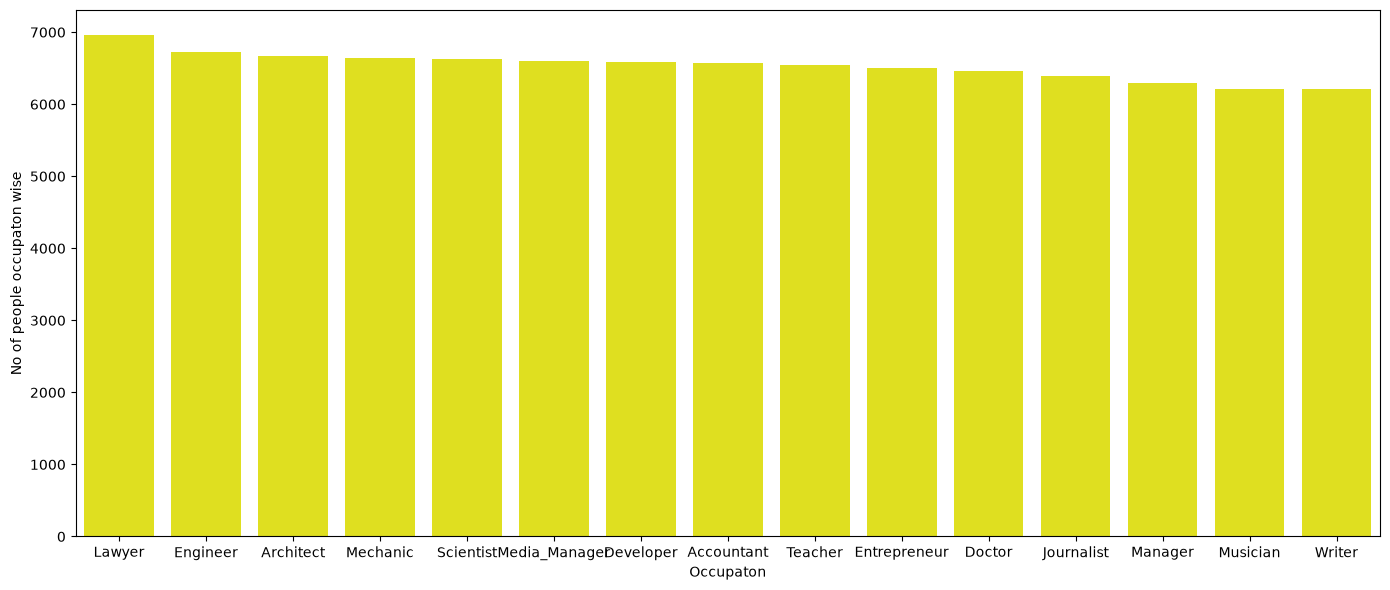

In [37]:
plt.figure(figsize=(14,6))
sns.countplot(data=df, x = 'Occupation', order =occupation_wise_no.index, color='yellow')
plt.ylabel('No of people occupaton wise')
plt.xlabel('Occupaton')

plt.tight_layout()
plt.show()

In [38]:
# No of customer by income group
max_income = df['Annual_Income'].max()
bins = [0, 25000, 50000, 100000, 200000]

labels = ['Low (<25K)', 'Lower-Middle (25K-50K)',
          'Middle (50K-100K)', 'Upper-Middle (100K-200K)'] 
df['Income_Group'] = pd.cut(df['Annual_Income'], bins=bins, labels=labels, include_lowest=True)

income_group_counts = df['Income_Group'].value_counts().sort_index()
print(income_group_counts)

Income_Group
Low (<25K)                  33480
Lower-Middle (25K-50K)      27296
Middle (50K-100K)           26496
Upper-Middle (100K-200K)    10728
Name: count, dtype: int64


#### financial Behaviour

In [39]:
#average yearly income
avg_yearly_income=df['Annual_Income'].mean()
print(avg_yearly_income)

48146.01715836735


In [40]:
Occupation_wise_income = df.groupby('Occupation')['Annual_Income'].sum().reset_index
print(Occupation_wise_income)

<bound method Series.reset_index of Occupation
Accountant       3.141720e+08
Architect        3.283849e+08
Developer        3.154482e+08
Doctor           3.062747e+08
Engineer         3.245303e+08
Entrepreneur     3.138129e+08
Journalist       2.927894e+08
Lawyer           3.293012e+08
Manager          3.075157e+08
Mechanic         3.183117e+08
Media_Manager    3.200553e+08
Musician         3.037369e+08
Scientist        3.251911e+08
Teacher          3.115764e+08
Writer           3.072092e+08
Name: Annual_Income, dtype: float64>


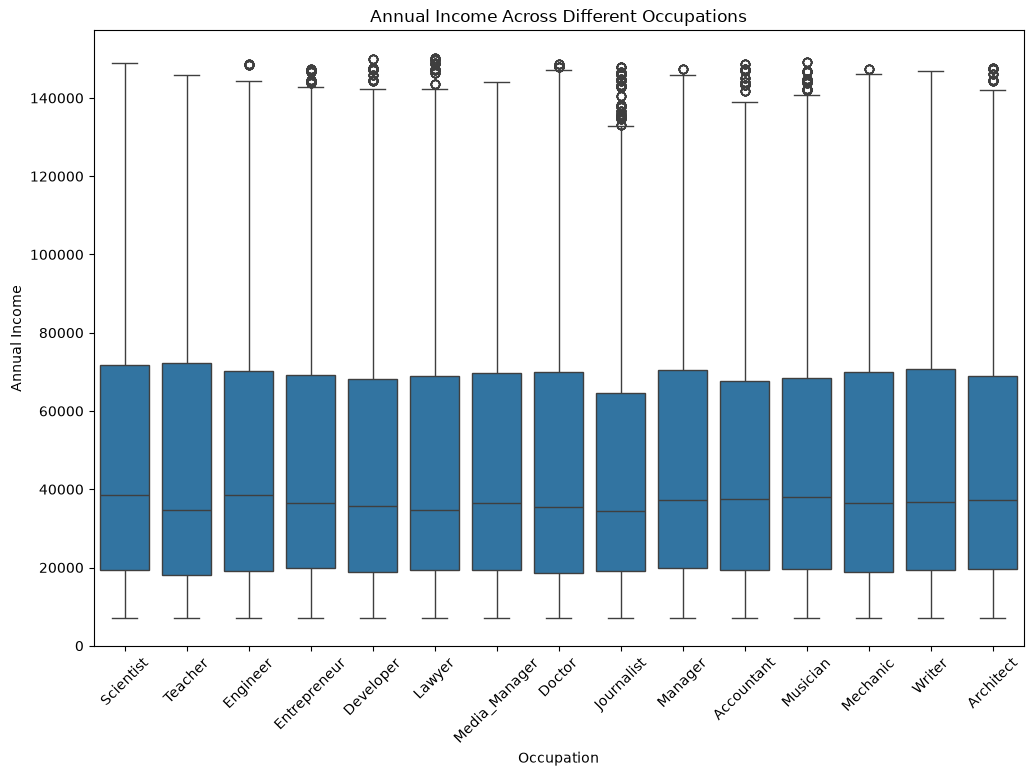

In [41]:
plt.figure(figsize=(12, 8))
sns.boxplot(data= df,x='Occupation', y='Annual_Income')
plt.xticks(rotation=45)
plt.title('Annual Income Across Different Occupations')
plt.xlabel('Occupation')
plt.ylabel('Annual Income')
plt.show()

In [42]:
# In hand monthly salary
avg_monthly_salary = df['Monthly_Inhand_Salary'].mean()
print(avg_monthly_salary)

4001.0791756356907


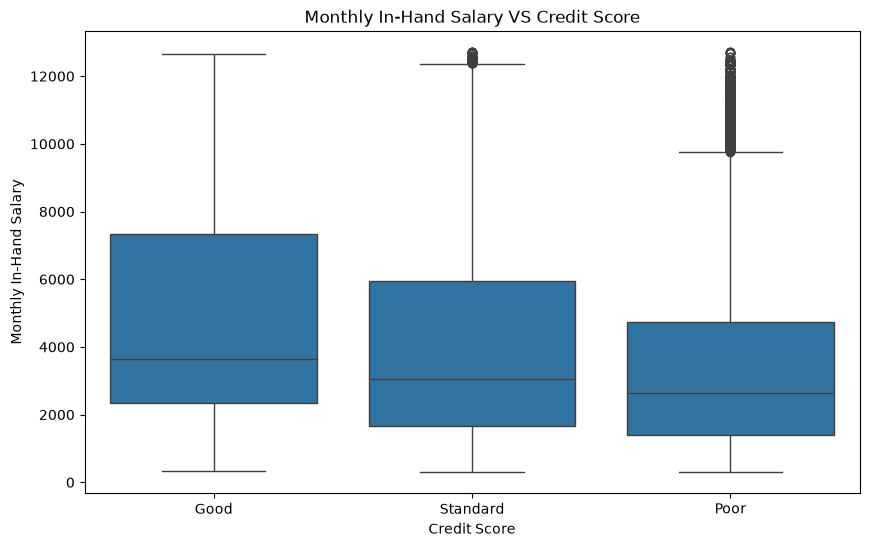

In [43]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df,x='Credit_Score', y='Monthly_Inhand_Salary')
plt.title('Monthly In-Hand Salary VS Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Monthly In-Hand Salary')
plt.show()

In [44]:
# debt and income ratio
debt_income_ratio = (df['Outstanding_Debt'] / df['Annual_Income']).mean()
print(debt_income_ratio)

0.06180580709358565


In [45]:
'''plt.figure(figsize=(10, 6))
sns.lineplot(x='Annual_Income', y='Outstanding_Debt', hue='Credit_Score', data=df)
plt.title('Outstanding Debt VS Annual Income (with Credit Score as Color)')
plt.xlabel('Annual Income')
plt.ylabel('Outstanding Debt')
plt.show()'''

"plt.figure(figsize=(10, 6))\nsns.lineplot(x='Annual_Income', y='Outstanding_Debt', hue='Credit_Score', data=df)\nplt.title('Outstanding Debt VS Annual Income (with Credit Score as Color)')\nplt.xlabel('Annual Income')\nplt.ylabel('Outstanding Debt')\nplt.show()"

In [46]:
#Average Bank Accounts numbers
no_avg_bank_accounts = df['Num_Bank_Accounts'].mean()
print(no_avg_bank_accounts)

5.423091836734694


In [47]:
#Average Number of Credit Cards
avg_no_credit_cards = df['Num_Credit_Card'].mean()
print(avg_no_credit_cards)

5.558387755102041


In [48]:
#Average Credit Utilization Ratio
avg_credit_utilization_ratio = df['Credit_Utilization_Ratio'].mean()
print(avg_credit_utilization_ratio)

32.21599199761475


<function matplotlib.pyplot.show(close=None, block=None)>

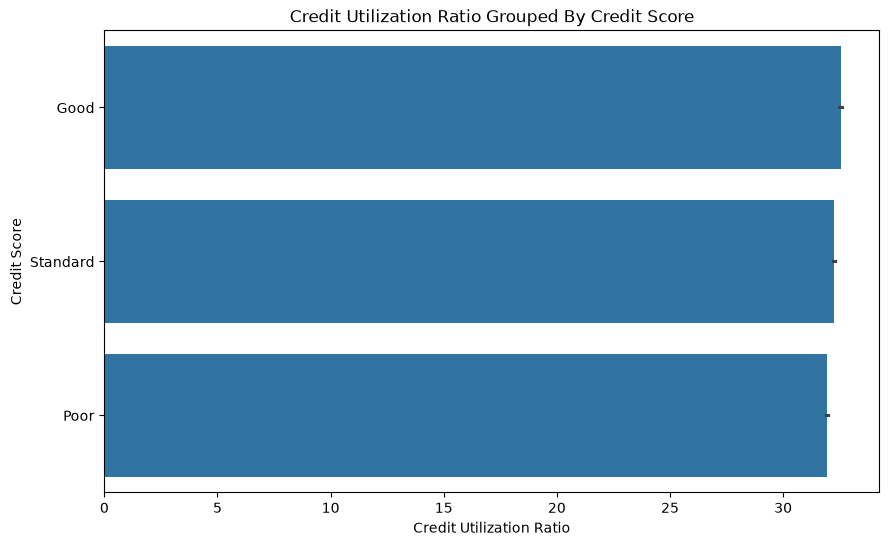

In [49]:
plt.figure(figsize=(10, 6))
sns.barplot(data = df, x='Credit_Utilization_Ratio', y='Credit_Score')
plt.title('Credit Utilization Ratio Grouped By Credit Score')
plt.xlabel('Credit Utilization Ratio')
plt.ylabel('Credit Score')
plt.show

#### credit score and loans

In [50]:
#Average Number of Loans per Customer
avg_no_loans = df['Num_of_Loan'].mean()
print(avg_no_loans)

3.565224489795918


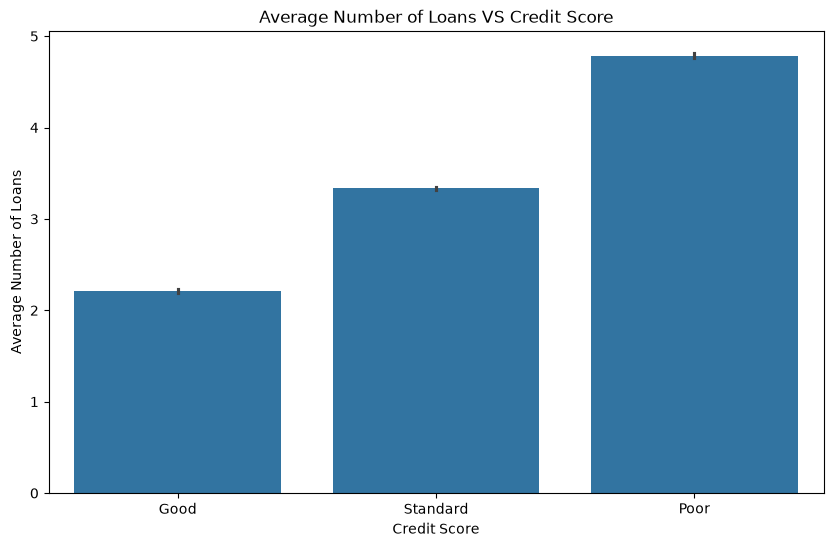

In [51]:
plt.figure(figsize=(10, 6))
sns.barplot(data= df,x='Credit_Score', y='Num_of_Loan')
plt.title('Average Number of Loans VS Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Average Number of Loans')
plt.show()

In [52]:
# burden ratio
total_EMI= df['Total_EMI_per_month'].sum()
yearly_income = df['Annual_Income'].sum()

total_burden_emi = (total_EMI / yearly_income) *100
print("total emi percentage to the income = " , total_burden_emi," % EMI of income")

total emi percentage to the income =  0.2183022750090028  % EMI of income


#### Risk and Fraud Indicator

In [53]:
# no of average delayed payment
avg_no_delay_payment= df['Num_of_Delayed_Payment'].mean()
print("average no of delayed payment = ",avg_no_delay_payment)

average no of delayed payment =  13.463285714285714


In [54]:
df.info()

<class 'pandas.DataFrame'>
Index: 98000 entries, 0 to 99999
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   ID                        98000 non-null  int64   
 1   Customer_ID               98000 non-null  int64   
 2   Month                     98000 non-null  int64   
 3   Name                      98000 non-null  str     
 4   Age                       98000 non-null  int64   
 5   SSN                       98000 non-null  float64 
 6   Occupation                98000 non-null  str     
 7   Annual_Income             98000 non-null  float64 
 8   Monthly_Inhand_Salary     98000 non-null  float64 
 9   Num_Bank_Accounts         98000 non-null  float64 
 10  Num_Credit_Card           98000 non-null  float64 
 11  Interest_Rate             98000 non-null  float64 
 12  Num_of_Loan               98000 non-null  float64 
 13  Type_of_Loan              98000 non-null  str     
 14  Delay_

In [55]:
#Percent of Customer with Frequent Credit Inquiries
percent_frequent_enquiries = (df['Num_Credit_Inquiries'] > 0).mean() * 100
print("average no of People who inquire frequently",percent_frequent_enquiries)

average no of People who inquire frequently 92.94183673469388


In [56]:
# avrage no of day delayed afterwards due date
avg_delay_from_due_date = df['Num_of_Delayed_Payment'].mean()
print("average of delayed payment afterwards due date:",avg_delay_from_due_date)

average of delayed payment afterwards due date: 13.463285714285714


In [57]:
# minimum and maximum day of delay from due date
min_delay_from_due_date = df['Num_of_Delayed_Payment'].min()
max_delay_from_due_date = df['Num_of_Delayed_Payment'].max()

print("min delay from due date:",min_delay_from_due_date)
print("miax delay from due date:",max_delay_from_due_date)

min delay from due date: 0
miax delay from due date: 25


#### Insight of behaviour of customer 

In [58]:
#Distribution of Payment Behaviour
payment_behaviour_counts = df['Payment_Behaviour'].value_counts()
print("Distribution of Payment Behaviour:",payment_behaviour_counts)

Distribution of Payment Behaviour: Payment_Behaviour
Low_spent_Small_value_payments      28436
High_spent_Medium_value_payments    19347
High_spent_Large_value_payments     14097
Low_spent_Medium_value_payments     13980
High_spent_Small_value_payments     11568
Low_spent_Large_value_payments      10572
Name: count, dtype: int64


In [59]:
payment_behaviour_counts =df['Payment_Behaviour'].value_counts()

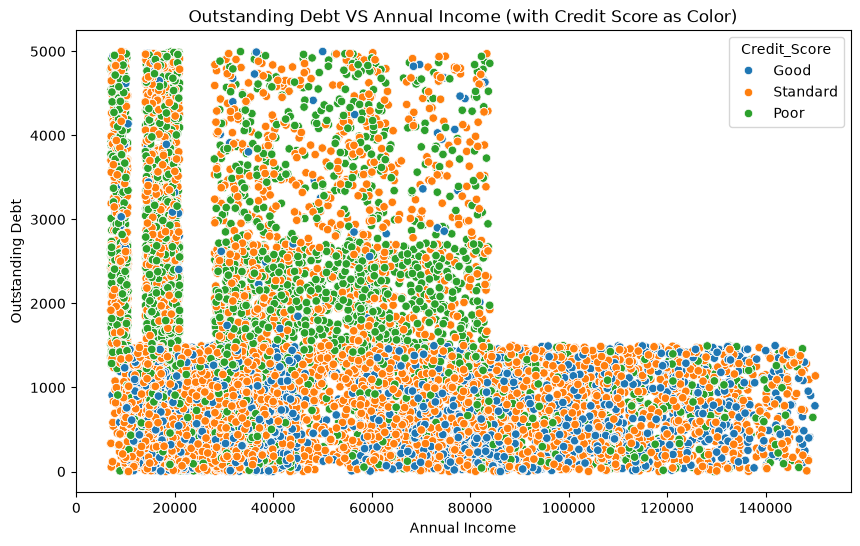

In [67]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Annual_Income', y='Outstanding_Debt', hue='Credit_Score', data=df)
plt.title('Outstanding Debt VS Annual Income (with Credit Score as Color)')
plt.xlabel('Annual Income')
plt.ylabel('Outstanding Debt')
plt.show()

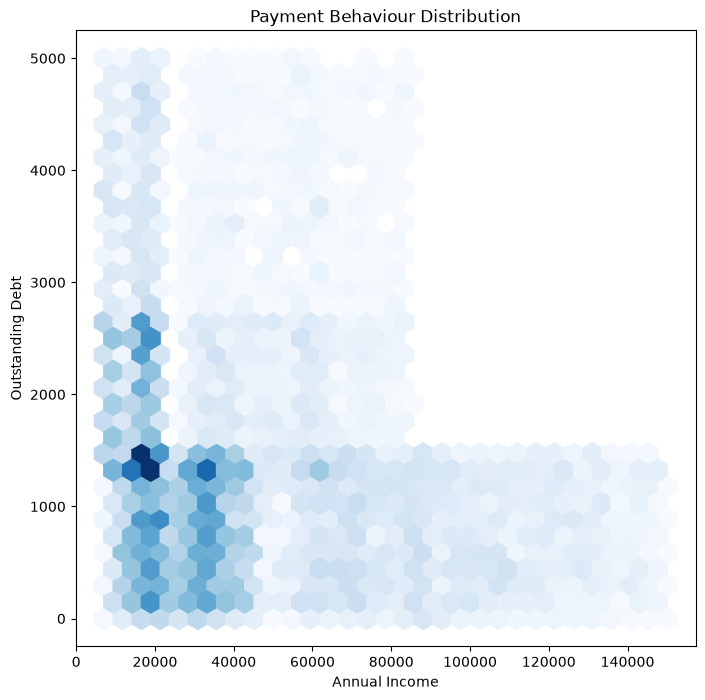

In [65]:
plt.figure(figsize=(8, 8))
plt.hexbin(
    df["Annual_Income"],
    df["Outstanding_Debt"],
    gridsize=30,
    cmap="Blues",
    mincnt=1,
)
plt.title('Payment Behaviour Distribution')
plt.xlabel('Annual Income')
plt.ylabel('Outstanding Debt')

plt.show()

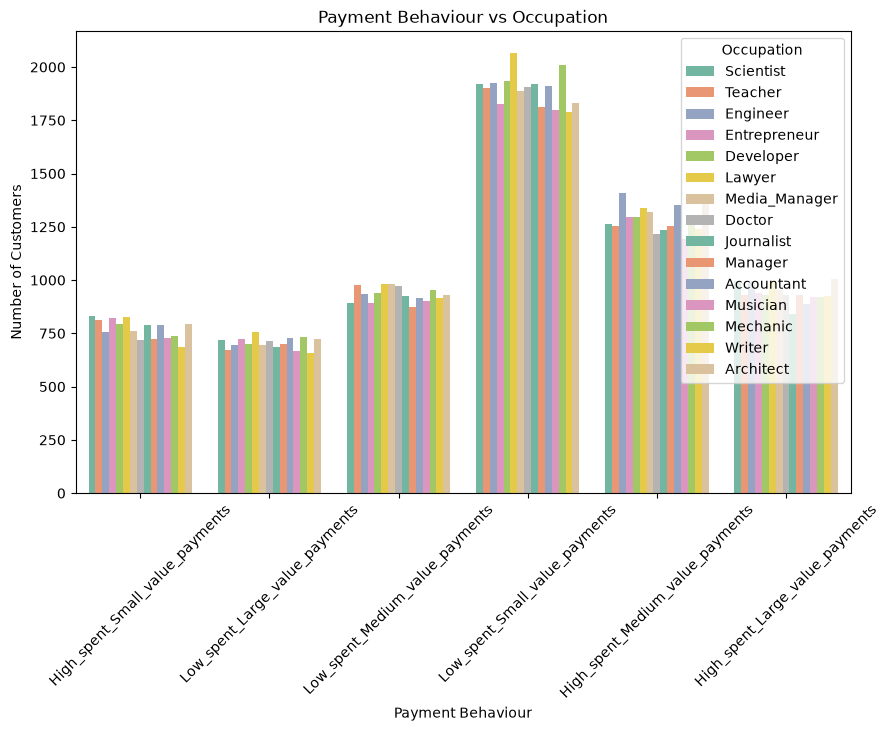

In [62]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Payment_Behaviour', hue='Occupation', palette='Set2')
plt.title("Payment Behaviour vs Occupation")
plt.xlabel("Payment Behaviour")
plt.ylabel("Number of Customers")
plt.legend(title="Occupation")
plt.xticks(rotation = 45)
plt.show()

In [63]:
#Percent of Customers who pay Minimum Amount only
percent_min_payment = (df['Payment_Behaviour'] == 'Low').mean() * 100
print("percentage of people who pay only minimum amount",percent_min_payment,"%")

percentage of people who pay only minimum amount 0.0 %


#### Average Debt, EMI, and Utilization across Credit Score Categories - Bar Chart (Overall Credit Score Analysis)

In [69]:
# Calculate averages across Credit Score categories
avg_metrics =df.groupby('Credit_Score')[['Outstanding_Debt','Total_EMI_per_month','Credit_Utilization_Ratio']].mean()
print(avg_metrics)

              Outstanding_Debt  Total_EMI_per_month  Credit_Utilization_Ratio
Credit_Score                                                                 
Good                806.538865           115.096083                 32.543324
Poor               2096.057017           109.846317                 31.942269
Standard           1286.645383            99.281164                 32.260084


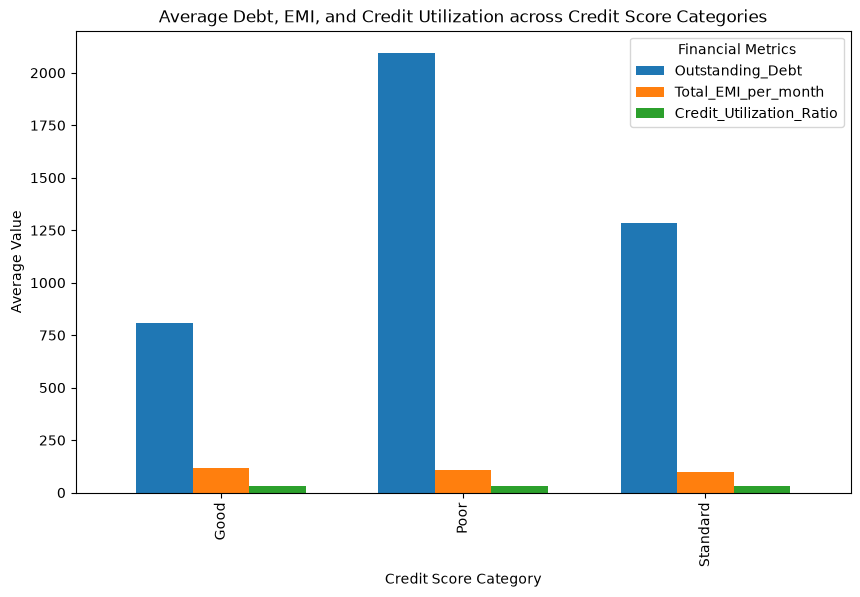

In [70]:
avg_metrics.plot(kind='bar', figsize=(10,6), width=0.7)

plt.title("Average Debt, EMI, and Credit Utilization across Credit Score Categories")
plt.xlabel("Credit Score Category")
plt.ylabel("Average Value")
plt.legend(title="Financial Metrics")
plt.show()